Importing the required libraries

In [157]:
import matplotlib.pyplot as plt 
import numpy as np 
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,accuracy_score,r2_score,mean_squared_error,mean_absolute_error
from xgboost import XGBRegressor 
import pandas as pd
import seaborn as sns

Load the Dataset

In [158]:
df = pd.read_csv('housing.csv')

Exploring the dataset

In [159]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [160]:
df = df.rename(columns={"median_house_value":"house_price"})

In [161]:
df['ocean_proximity'] = df['ocean_proximity'].replace("<1H OCEAN","NEAR OCEAN")

In [162]:
df['ocean_proximity'].unique()

<ArrowStringArray>
['NEAR BAY', 'NEAR OCEAN', 'INLAND', 'ISLAND']
Length: 4, dtype: str

In [163]:
df = pd.get_dummies(df, columns=['ocean_proximity'])

In [164]:
df.isnull().sum()

longitude                       0
latitude                        0
housing_median_age              0
total_rooms                     0
total_bedrooms                207
population                      0
households                      0
median_income                   0
house_price                     0
ocean_proximity_INLAND          0
ocean_proximity_ISLAND          0
ocean_proximity_NEAR BAY        0
ocean_proximity_NEAR OCEAN      0
dtype: int64

In [165]:
df['rooms_per_household'] = df['total_rooms']/ df['households']
df['bedrooms_per_room'] = df['total_bedrooms'] / df['total_rooms']
df['population_per_households'] = df['population'] / df['households']
df.drop(columns=['total_rooms','total_bedrooms','households'],inplace=True)
df.shape

(20640, 13)

In [166]:
median_bedrooms = df['bedrooms_per_room'].median()
df['bedrooms_per_room'] = df['bedrooms_per_room'].fillna(median_bedrooms)

In [167]:
df.drop_duplicates(inplace=True)
df.shape

(20640, 13)

In [168]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   longitude                   20640 non-null  float64
 1   latitude                    20640 non-null  float64
 2   housing_median_age          20640 non-null  float64
 3   population                  20640 non-null  float64
 4   median_income               20640 non-null  float64
 5   house_price                 20640 non-null  float64
 6   ocean_proximity_INLAND      20640 non-null  bool   
 7   ocean_proximity_ISLAND      20640 non-null  bool   
 8   ocean_proximity_NEAR BAY    20640 non-null  bool   
 9   ocean_proximity_NEAR OCEAN  20640 non-null  bool   
 10  rooms_per_household         20640 non-null  float64
 11  bedrooms_per_room           20640 non-null  float64
 12  population_per_households   20640 non-null  float64
dtypes: bool(4), float64(9)
memory usage: 1.5 M

DATA VISUALIZATION

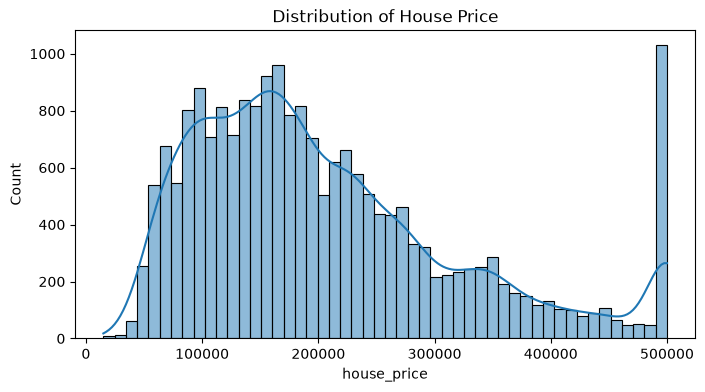

In [169]:
# Distribution of house price

plt.figure(figsize=(8,4))
sns.histplot(df['house_price'], bins=50, kde=True)
plt.title('Distribution of House Price')
plt.show()



Why: house_price is the target you want to predict, so you need to know its shape first.


What to look for: Prices are mostly in the lower-to-mid range, with a long tail toward expensive houses. This dataset also has a spike at the far right, because prices above about 500,000 are capped. A model will find it hard to predict those capped houses.

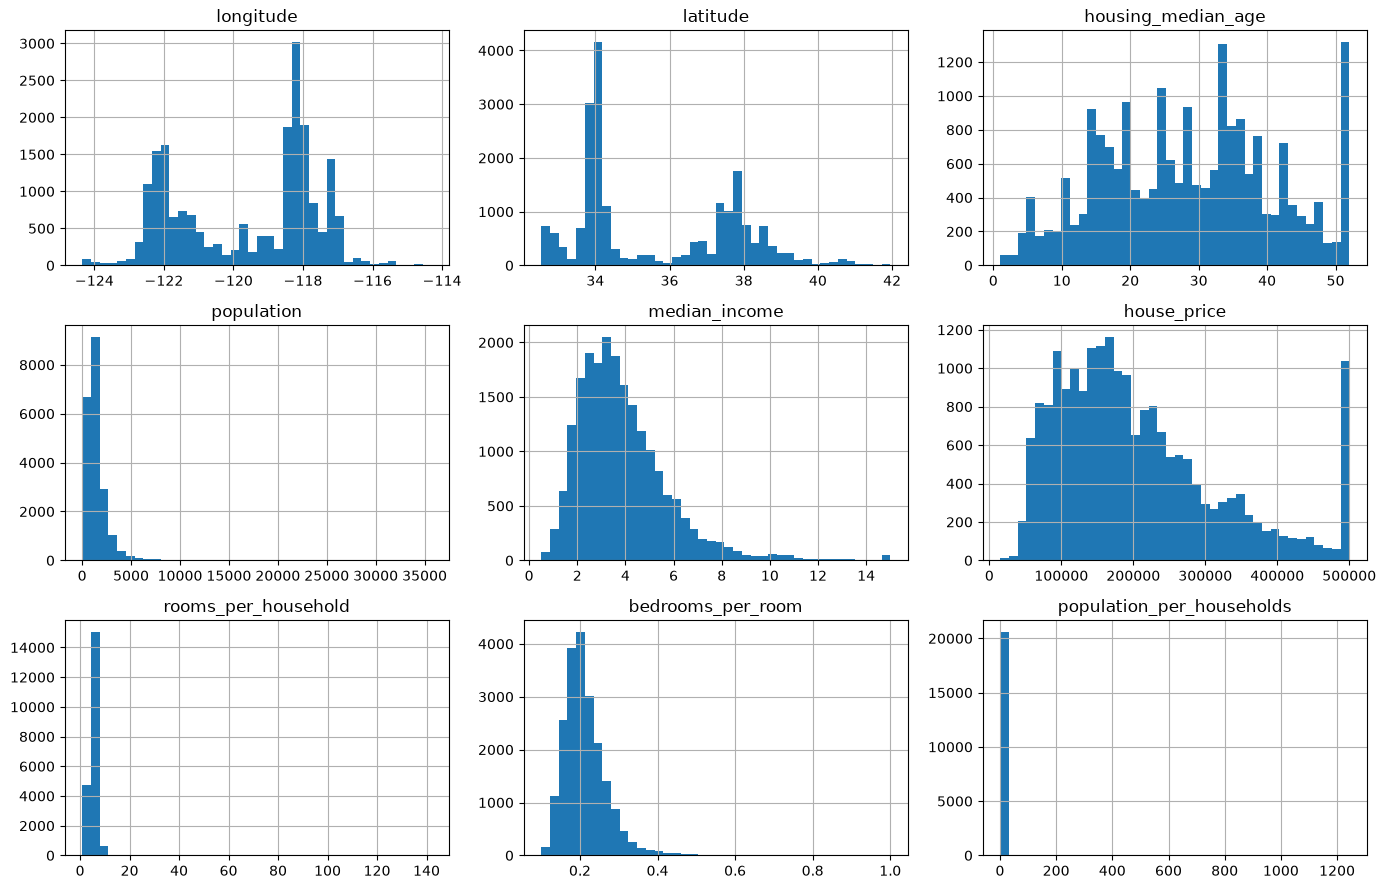

In [170]:
# Histograms of all numeric columns

num_cols = ['longitude','latitude','housing_median_age','population','median_income',
            'house_price','rooms_per_household','bedrooms_per_room','population_per_households']
df[num_cols].hist(bins=40, figsize=(14,9))
plt.tight_layout()
plt.show()

Why: It shows the spread of every feature in one view.

What to look for: Some columns are skewed, such as population, median_income and rooms_per_household, with a few very large values. Others, like housing_median_age, are more even, with a pile-up at the maximum age of 52.

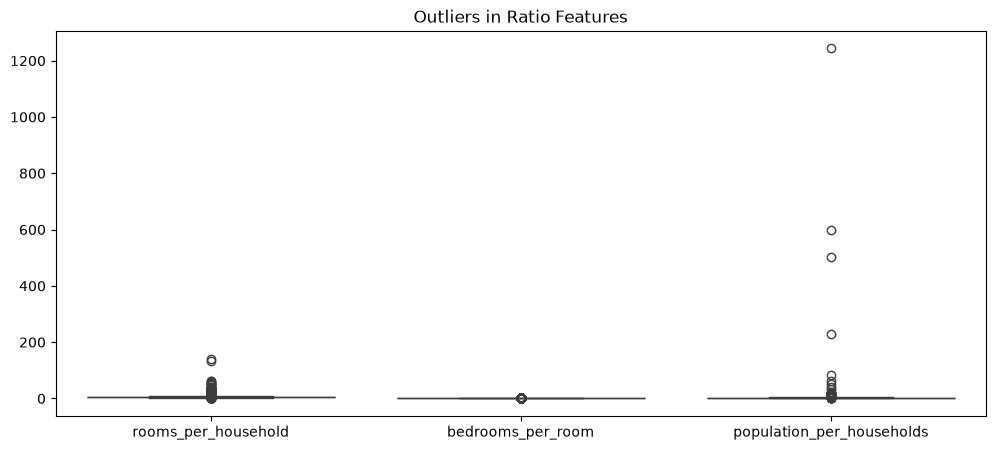

In [171]:
# Boxplots (outlier check)

plt.figure(figsize=(12,5))
sns.boxplot(data=df[['rooms_per_household','bedrooms_per_room','population_per_households']])
plt.title('Outliers in Ratio Features')
plt.show()

Why: Outliers can mislead a model, and boxplots show them as dots far from the box.

What to look for: rooms_per_household and population_per_households have extreme points. These are probably unusual areas such as resort towns or areas with very few households.

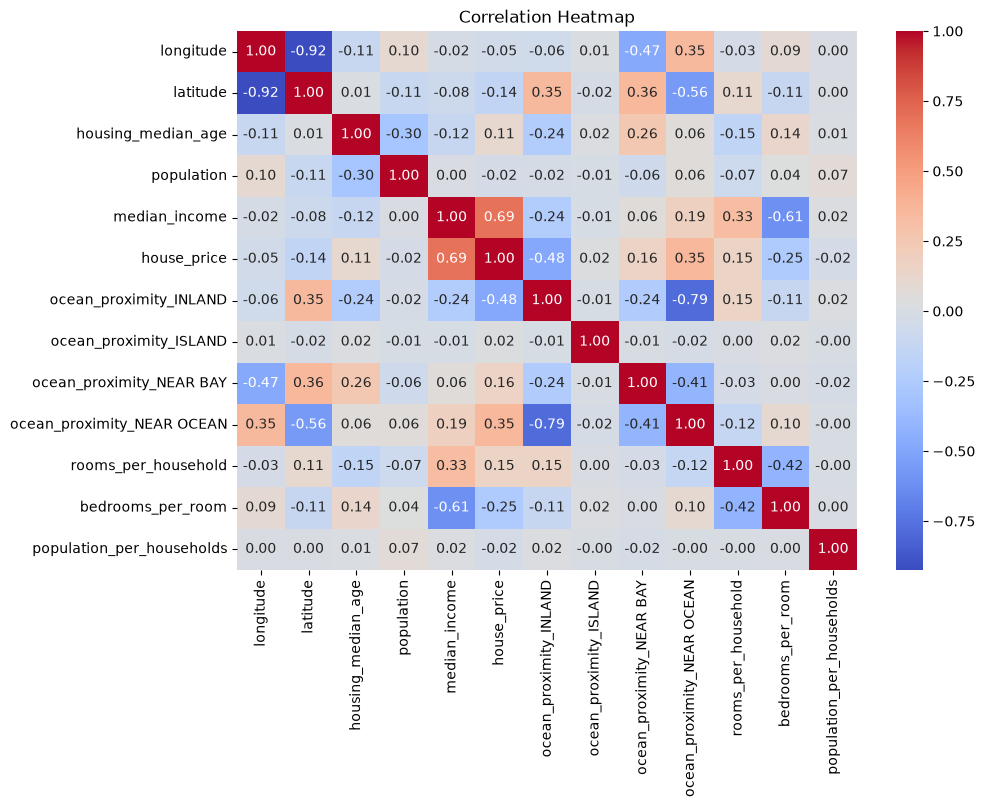

In [172]:
# Correlation heatmap

plt.figure(figsize=(10,7))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

Why: It shows how strongly each feature moves with house_price and with the other features.

What to look for: Check the house_price row. median_income should have the strongest positive correlation, and ocean_proximity_INLAND should be negative. Two features that correlate strongly with each other carry the same information.

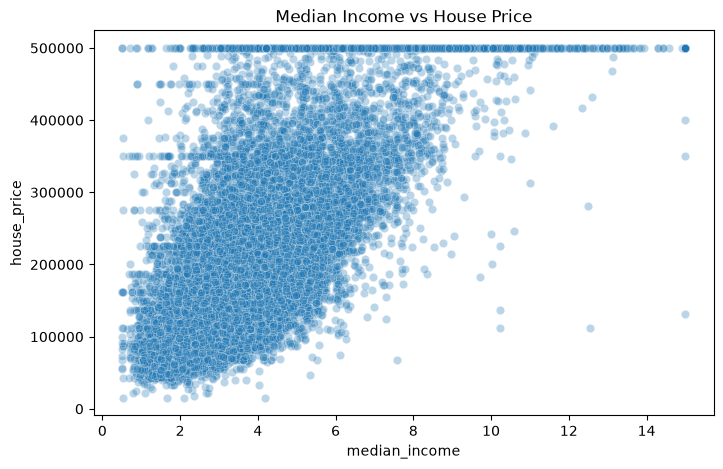

In [173]:
# Income vs house price

plt.figure(figsize=(8,5))
sns.scatterplot(x='median_income', y='house_price', data=df, alpha=0.3)
plt.title('Median Income vs House Price')
plt.show()

Why: It confirms the strongest relationship from the heatmap.

What to look for: Prices rise as income rises. You’ll also see a flat horizontal line at the top, which is the price cap.

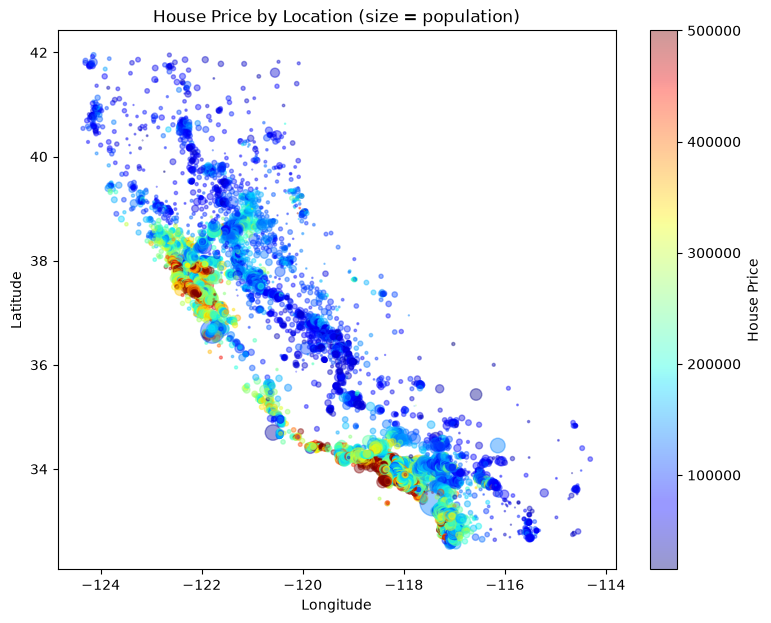

In [174]:
# Location map colored by price

plt.figure(figsize=(9,7))
plt.scatter(df['longitude'], df['latitude'], c=df['house_price'],
            cmap='jet', s=df['population']/100, alpha=0.4)
plt.colorbar(label='House Price')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('House Price by Location (size = population)')
plt.show()

Why: Location is often the biggest driver of price.

What to look for: The points draw the shape of California. Expensive areas (red) cluster along the coast, around the San Francisco Bay and Los Angeles, and cheaper areas (blue) are inland.

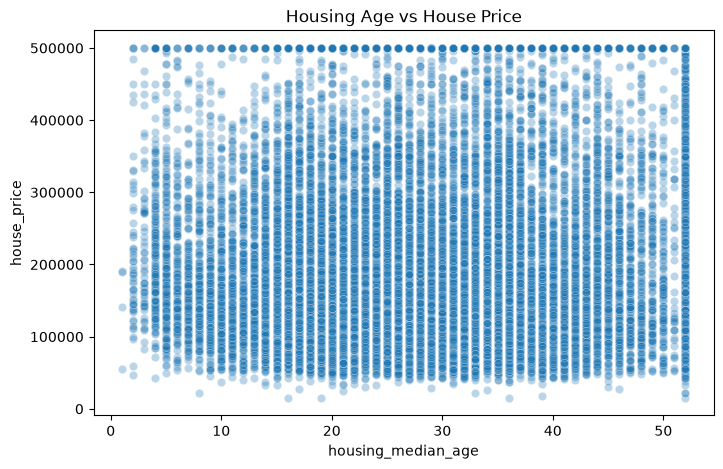

In [175]:
# Age vs price

plt.figure(figsize=(8,5))
sns.scatterplot(x='housing_median_age', y='house_price', data=df, alpha=0.3)
plt.title('Housing Age vs House Price')
plt.show()

Why: It tests whether older or newer areas cost more.

What to look for: The relationship is weak and scattered, so age alone is a poor predictor. It still may help the model in combination with other features.

What you learn overall : 

Target: prices are skewed and capped.
Strongest feature: median_income.
Location: coast vs inland matters a lot.
Data quality: some features have outliers worth handling before training the XGBoost model.

HANDLING THE OUTLIERS 

In [176]:
# columns to treat

outlier_cols = ['population', 'median_income', 'rooms_per_household',
                'bedrooms_per_room', 'population_per_households']

What and why: These columns are continuous numbers where extreme values can occur. I left out the following columns on purpose:

longitude and latitude are locations, so they aren’t outliers.
The ocean_proximity_* columns are just True/False.
house_price is the target, and we don’t want to change what we predict.

In [177]:
# Count the outliers (before)

def count_outliers(data, col):
    Q1 = data[col].quantile(0.25)   # 25% of values are below this
    Q3 = data[col].quantile(0.75)   # 75% of values are below this
    IQR = Q3 - Q1                   # the "normal" middle spread
    lower = Q1 - 1.5 * IQR          # anything below this is too small
    upper = Q3 + 1.5 * IQR          # anything above this is too large
    return ((data[col] < lower) | (data[col] > upper)).sum()

print("Outliers BEFORE handling:")
for col in outlier_cols:
    print(col, ":", count_outliers(df, col))

Outliers BEFORE handling:
population : 1196
median_income : 681
rooms_per_household : 511
bedrooms_per_room : 604
population_per_households : 711


What and why: We use the IQR rule, a standard and simple way to define an outlier:

Q1 and Q3 mark where the middle 50% of the data lies.
IQR is the width of that middle part.
A value more than 1.5 × IQR beyond Q1 or Q3 is called an outlier.

We count first so we can compare with the result afterward.

In [178]:
# Cap the outliers

for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # clip: values below 'lower' become 'lower', values above 'upper' become 'upper'
    df[col] = df[col].clip(lower, upper)

What and why: This is called capping. We don’t delete the extreme rows. We pull them back to the boundary value.

Capping is better than deleting here for two reasons:

We keep all 20,640 rows, so we don’t lose data.
The extreme values stop dominating the model, and the row’s other information is still used.

In [179]:
# Check the result (after)

print("Outliers AFTER handling:")
for col in outlier_cols:
    print(col, ":", count_outliers(df, col))

print("Shape:", df.shape)

Outliers AFTER handling:
population : 0
median_income : 0
rooms_per_household : 0
bedrooms_per_room : 0
population_per_households : 0
Shape: (20640, 13)


What and why: The counts should now be 0, or very close to it. Occasionally a few points remain, because capping changes the quartiles slightly. The shape should still be (20640, 13), which confirms no rows were lost

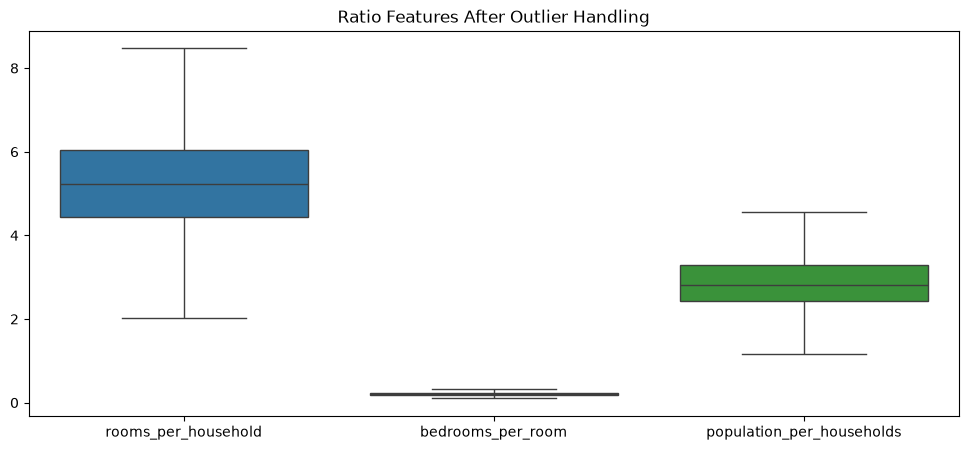

In [180]:
# Visual proof

plt.figure(figsize=(12,5))
sns.boxplot(data=df[['rooms_per_household','bedrooms_per_room','population_per_households']])
plt.title('Ratio Features After Outlier Handling')
plt.show()

What and why: Compare this with the boxplot you made earlier. The far-away dots should be gone, and the boxes are now readable.

Separate features and target

In [181]:
X = df.drop(columns=['house_price'])   # input features
y = df['house_price']                  # what we want to predict

Split into train and test

In [182]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Train size: (16512, 12)
Test size: (4128, 12)


Create and train the model

In [183]:
model = XGBRegressor(
    n_estimators=200,      # number of trees built one after another
    learning_rate=0.1,     # how much each new tree corrects the previous ones
    max_depth=3,           # how deep each tree can go
    random_state=42
)

model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


Predict

In [184]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

What and why: The model predicts prices for both the training houses and the unseen test houses. We need both so we can compare them in the next step.

In [185]:
# Evaluate

def show_scores(name, y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    print(f"{name}:  R2 = {r2:.3f} | RMSE = {rmse:,.0f} | MAE = {mae:,.0f}")

show_scores("Train", y_train, y_train_pred)
show_scores("Test ", y_test, y_test_pred)

Train:  R2 = 0.835 | RMSE = 46,964 | MAE = 32,442
Test :  R2 = 0.803 | RMSE = 50,783 | MAE = 34,344


What each score means:

R²: how much of the price variation the model explains. 1.0 is perfect and 0 is no better than guessing the average.
MAE: the average error in dollars. If it is 30,000, the predictions are off by about $30,000 on average.
RMSE: similar to MAE, but it penalizes big mistakes more.

Overfitting check: If the train R² is much higher than the test R² (for example 0.98 vs 0.83), the model is memorizing rather than learning. In that case, lower max_depth or n_estimators.

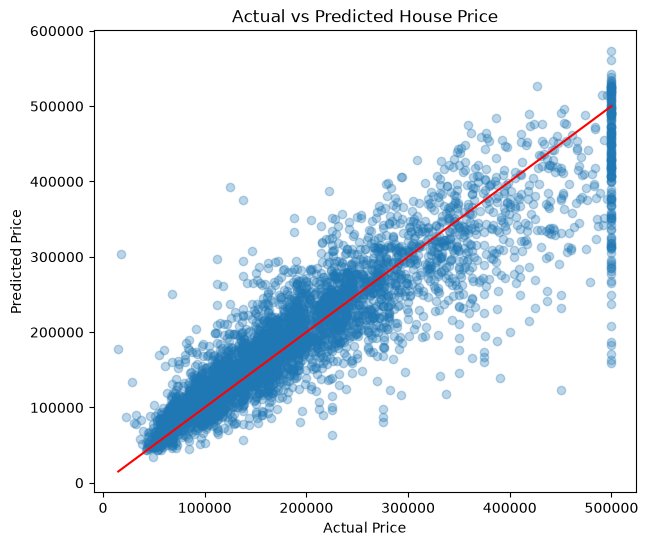

In [186]:
# Actual vs predicted plot

plt.figure(figsize=(7,6))
plt.scatter(y_test, y_test_pred, alpha=0.3)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red')   # perfect-prediction line
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted House Price')
plt.show()

What and why: If the model were perfect, every dot would sit on the red line. The closer the dots are to it, the better. Expect the most error for the expensive houses, because of the price cap you saw earlier.

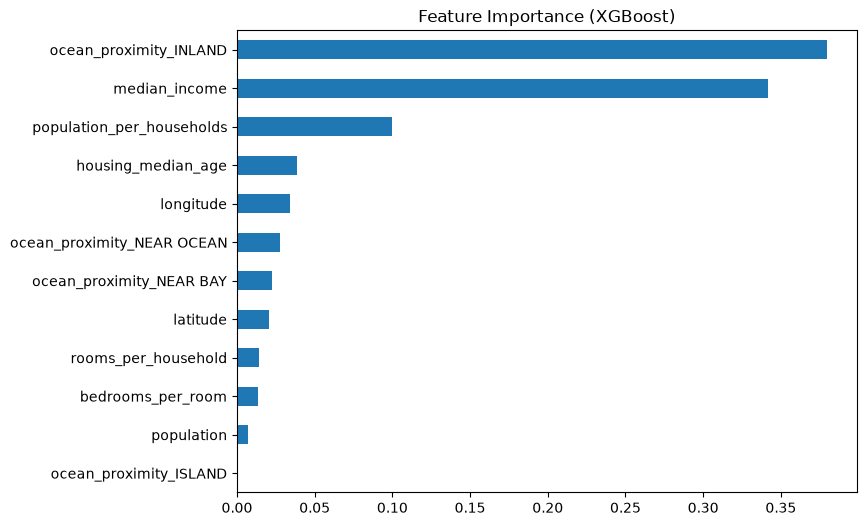

In [187]:
# Feature importance

importance = pd.Series(model.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8,6))
importance.plot(kind='barh')
plt.title('Feature Importance (XGBoost)')
plt.show()

What and why: It shows which features the model relied on most to predict price. This helps you understand the model and compare it against your earlier heatmap. median_income and the location columns (longitude, latitude, ocean_proximity_INLAND) are the likely top features.